# Data generation & calculating the default rate 

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random

# Set seed for reproducibility
np.random.seed(42)

def generate_credit_dataset(n_customers=10000):
    """Generate synthetic credit risk dataset with realistic patterns"""
    
    # Customer Demographics
    customer_id = [f'C{1000+i}' for i in range(n_customers)]
    age = np.random.randint(22, 65, n_customers)
    gender = np.random.choice(['Male', 'Female'], n_customers, p=[0.55, 0.45])
    income = np.random.normal(50000, 25000, n_customers).astype(int)
    income = np.maximum(income, 15000)  # Minimum income
    
    # Employment
    employment_types = ['Salaried', 'Self-Employed', 'Business', 'Retired']
    employment_type = np.random.choice(employment_types, n_customers, 
                                      p=[0.55, 0.20, 0.15, 0.10])
    employment_years = np.random.exponential(8, n_customers).astype(int)
    employment_years = np.minimum(employment_years, 40)
    
    # Credit Profile
    credit_score = np.random.normal(700, 50, n_customers).astype(int)
    credit_score = np.clip(credit_score, 300, 850)
    
    credit_history = np.random.choice(['Good', 'Fair', 'Poor'], n_customers,
                                     p=[0.60, 0.25, 0.15])
    
    # Existing Debt
    existing_loans = np.random.poisson(1.5, n_customers)
    existing_loans = np.minimum(existing_loans, 5)
    
    outstanding_debt = income * np.random.uniform(0.1, 0.6, n_customers)
    outstanding_debt = outstanding_debt.astype(int)
    
    # Loan Details
    loan_amount = income * np.random.uniform(2, 8, n_customers)
    loan_amount = loan_amount.astype(int)
    loan_amount = np.clip(loan_amount, 50000, 5000000)
    
    loan_term = np.random.choice([12, 24, 36, 48, 60], n_customers,
                                 p=[0.1, 0.2, 0.3, 0.25, 0.15])
    
    interest_rate = np.random.normal(12, 4, n_customers)
    interest_rate = np.clip(interest_rate, 6, 24).round(2)
    
    # Repayment Behavior
    late_payments = np.random.poisson(0.5, n_customers)
    late_payments = np.minimum(late_payments, 10)
    
    missed_payments = np.random.poisson(0.2, n_customers)
    missed_payments = np.minimum(missed_payments, 5)
    
    # Banking Behavior
    avg_balance = np.random.lognormal(10, 2, n_customers)
    avg_balance = np.clip(avg_balance, 1000, 1000000).astype(int)
    
    transaction_frequency = np.random.poisson(15, n_customers)
    transaction_frequency = np.clip(transaction_frequency, 0, 50)
    
    # Calculate derived features
    monthly_emi = (loan_amount * (interest_rate/1200) * (1 + interest_rate/1200)**(loan_term*12)) / \
                  ((1 + interest_rate/1200)**(loan_term*12) - 1)
    monthly_emi = np.round(monthly_emi, 2)
    
    dti_ratio = ((monthly_emi + (outstanding_debt / 12)) / (income / 12)) * 100
    dti_ratio = np.clip(dti_ratio, 0, 80)
    
    credit_utilization = (outstanding_debt / (income * 2)) * 100
    credit_utilization = np.clip(credit_utilization, 0, 100)
    
    # Target variable (Default) - based on realistic risk factors
    risk_score = (1 - (credit_score/850)) * 0.3 + \
                 (late_payments/10) * 0.25 + \
                 (missed_payments/5) * 0.2 + \
                 (dti_ratio/80) * 0.15 + \
                 (credit_utilization/100) * 0.1
    
    # Add some randomness
    risk_score = np.clip(risk_score + np.random.normal(0, 0.05, n_customers), 0, 1)
    
    default = (risk_score > np.random.uniform(0.25, 0.45, n_customers)).astype(int)
    
    # Create DataFrame
    df = pd.DataFrame({
        'customer_id': customer_id,
        'age': age,
        'gender': gender,
        'income': income,
        'employment_type': employment_type,
        'employment_years': employment_years,
        'credit_score': credit_score,
        'credit_history': credit_history,
        'existing_loans': existing_loans,
        'outstanding_debt': outstanding_debt,
        'loan_amount': loan_amount,
        'loan_term': loan_term,
        'interest_rate': interest_rate,
        'late_payments': late_payments,
        'missed_payments': missed_payments,
        'avg_balance': avg_balance,
        'transaction_frequency': transaction_frequency,
        'monthly_emi': monthly_emi,
        'dti_ratio': dti_ratio,
        'credit_utilization': credit_utilization,
        'default': default,
        'risk_score': risk_score
    })
    
    return df

# Generate dataset
df = generate_credit_dataset(10000)
print(f"Dataset Shape: {df.shape}")
print(f"Default Rate: {df['default'].mean():.2%}")

Dataset Shape: (10000, 22)
Default Rate: 8.68%


In [2]:
df.describe()
df.isnull().sum()


customer_id              0
age                      0
gender                   0
income                   0
employment_type          0
employment_years         0
credit_score             0
credit_history           0
existing_loans           0
outstanding_debt         0
loan_amount              0
loan_term                0
interest_rate            0
late_payments            0
missed_payments          0
avg_balance              0
transaction_frequency    0
monthly_emi              0
dti_ratio                0
credit_utilization       0
default                  0
risk_score               0
dtype: int64

# EDA visulaisation

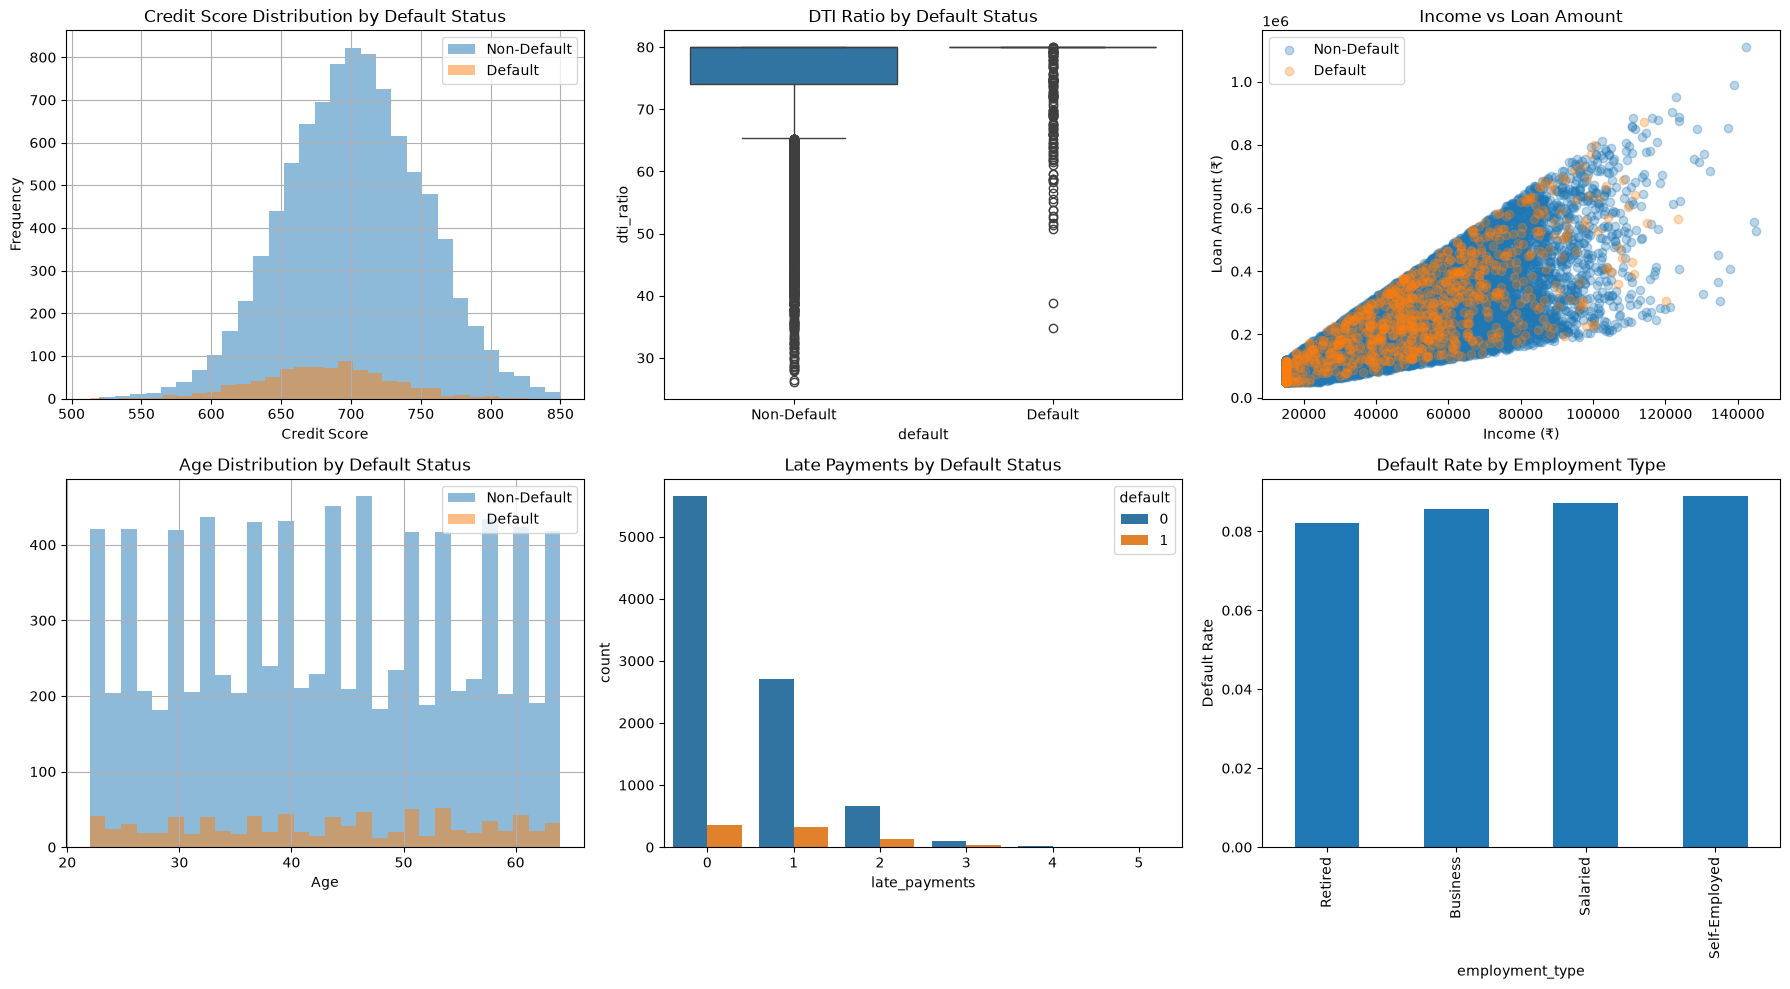

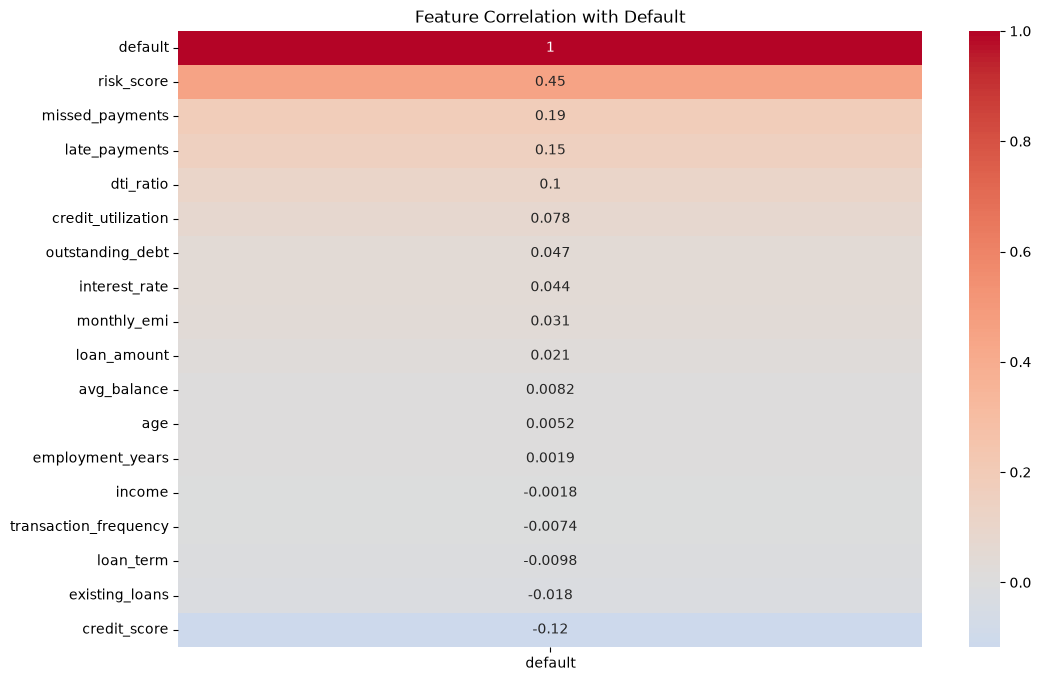

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


def perform_eda(df):
  """Comprehensive EDA for credit risk"""

  fig, axes = plt.subplots(2, 3, figsize=(18, 10))

  # 1. Credit Score Distribution
  ax1 = axes[0, 0]
  df[df['default'] == 0]['credit_score'].hist(
      ax=ax1, alpha=0.5, bins=30, label='Non-Default'
  )
  df[df['default'] == 1]['credit_score'].hist(
      ax=ax1, alpha=0.5, bins=30, label='Default'
  )
  ax1.set_title('Credit Score Distribution by Default Status')
  ax1.set_xlabel('Credit Score')
  ax1.set_ylabel('Frequency')
  ax1.legend()

  # 2. DTI Ratio vs Default (Warning fixed here)
  ax2 = axes[0, 1]
  sns.boxplot(x='default', y='dti_ratio', data=df, ax=ax2)
  ax2.set_title('DTI Ratio by Default Status')
  ax2.set_xticks([0, 1])
  ax2.set_xticklabels(['Non-Default', 'Default'])

  # 3. Income vs Loan Amount
  ax3 = axes[0, 2]
  ax3.scatter(
      df[df['default'] == 0]['income'],
      df[df['default'] == 0]['loan_amount'],
      alpha=0.3,
      label='Non-Default',
  )
  ax3.scatter(
      df[df['default'] == 1]['income'],
      df[df['default'] == 1]['loan_amount'],
      alpha=0.3,
      label='Default',
  )
  ax3.set_title('Income vs Loan Amount')
  ax3.set_xlabel('Income (₹)')
  ax3.set_ylabel('Loan Amount (₹)')
  ax3.legend()

  # 4. Age Distribution
  ax4 = axes[1, 0]
  df[df['default'] == 0]['age'].hist(
      ax=ax4, alpha=0.5, bins=30, label='Non-Default'
  )
  df[df['default'] == 1]['age'].hist(
      ax=ax4, alpha=0.5, bins=30, label='Default'
  )
  ax4.set_title('Age Distribution by Default Status')
  ax4.set_xlabel('Age')
  ax4.legend()

  # 5. Late Payments
  ax5 = axes[1, 1]
  sns.countplot(
      x='late_payments',
      hue='default',
      data=df[df['late_payments'] <= 5],
      ax=ax5,
  )
  ax5.set_title('Late Payments by Default Status')

  # 6. Employment Type
  ax6 = axes[1, 2]
  default_by_emp = df.groupby('employment_type')['default'].mean().sort_values()
  default_by_emp.plot(kind='bar', ax=ax6)
  ax6.set_title('Default Rate by Employment Type')
  ax6.set_ylabel('Default Rate')

  plt.tight_layout()
  plt.show()

  # Correlation Analysis
  plt.figure(figsize=(12, 8))
  numeric_cols = df.select_dtypes(include=[np.number]).columns
  correlation_matrix = df[numeric_cols].corr()
  sns.heatmap(
      correlation_matrix[['default']].sort_values(
          by='default', ascending=False
      ),
      annot=True,
      cmap='coolwarm',
      center=0,
  )
  plt.title('Feature Correlation with Default')
  plt.show()

  return correlation_matrix


# Execute the function to see your plots
correlation_matrix = perform_eda(df)

In [4]:
import pandas as pd

# 1. DEFINE THE FUNCTION FIRST
def create_risk_segments(df):
    """Create business-oriented risk segments"""
    
    # Define risk buckets based on credit score and DTI
    def risk_category(row):
        if row['credit_score'] >= 750 and row['dti_ratio'] < 30:
            return 'Low Risk'
        elif row['credit_score'] >= 650 and row['dti_ratio'] < 45:
            return 'Medium Risk'
        elif row['credit_score'] >= 550 and row['dti_ratio'] < 60:
            return 'High Risk'
        else:
            return 'Very High Risk'
    
    df['risk_category'] = df.apply(risk_category, axis=1)
    
    # Calculate default rates per category
    risk_summary = df.groupby('risk_category').agg({
        'default': ['mean', 'count'],
        'income': 'mean',
        'loan_amount': 'mean',
        'credit_score': 'mean'
    }).round(2)
    
    return df, risk_summary


# 2. RUN A SANITY CHECK ON YOUR DATAFRAME
print("Checking DataFrame shape:", df.shape)


# 3. CALL THE FUNCTION AND DISPLAY OUTPUT
df, risk_summary = create_risk_segments(df)

# Print explicitly
print("\nRisk Segmentation Summary:")
display(risk_summary)

Checking DataFrame shape: (10000, 22)

Risk Segmentation Summary:


default          income loan_amount credit_score
                  mean count      mean        mean         mean
risk_category                                                  
High Risk         0.02   842  52495.83   170738.65       694.24
Medium Risk       0.01   196  51229.44   140109.30       715.49
Very High Risk    0.09  8962  51059.84   267367.01       699.93

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['default'])
y = df['default']
# Split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Default rate - Train: {y_train.mean():.2%}, Test: {y_test.mean():.2%}")

Training set: (7500, 22)
Test set: (2500, 22)
Default rate - Train: 8.68%, Test: 8.68%



Training Logistic Regression...

Logistic Regression Results:
AUC-ROC: 0.7480

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.80      2283
           1       0.17      0.67      0.27       217

    accuracy                           0.69      2500
   macro avg       0.56      0.68      0.54      2500
weighted avg       0.89      0.69      0.76      2500

Confusion Matrix:
[[1581  702]
 [  72  145]]

Training Random Forest...



Random Forest Results:
AUC-ROC: 0.7117

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      2283
           1       0.26      0.11      0.16       217

    accuracy                           0.90      2500
   macro avg       0.59      0.54      0.55      2500
weighted avg       0.86      0.90      0.88      2500

Confusion Matrix:
[[2216   67]
 [ 193   24]]

Training Gradient Boosting...



Gradient Boosting Results:
AUC-ROC: 0.7387

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.99      0.95      2283
           1       0.33      0.06      0.09       217

    accuracy                           0.91      2500
   macro avg       0.63      0.52      0.52      2500
weighted avg       0.87      0.91      0.88      2500

Confusion Matrix:
[[2259   24]
 [ 205   12]]


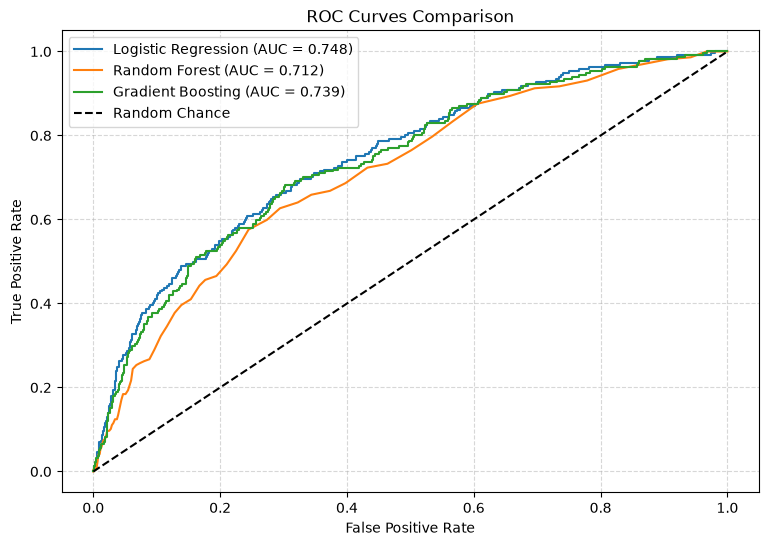

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ==========================================
# 1. PREPARE FEATURES CLEANLY
# ==========================================


def prepare_features(df):
  """Prepare features for modeling by encoding categorical columns and removing IDs"""

  # Numerical features
  numerical_features = [
      'age',
      'income',
      'employment_years',
      'credit_score',
      'existing_loans',
      'outstanding_debt',
      'loan_amount',
      'loan_term',
      'interest_rate',
      'late_payments',
      'missed_payments',
      'avg_balance',
      'transaction_frequency',
      'monthly_emi',
      'dti_ratio',
      'credit_utilization',
  ]

  # Categorical features
  categorical_features = ['employment_type', 'credit_history', 'gender']

  # Create feature matrix (X) and target (y)
  X = df[numerical_features + categorical_features].copy()
  y = df['default']

  # Encode text categorical variables into numbers
  le_dict = {}
  for col in categorical_features:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    le_dict[col] = le

  return X, y, le_dict


# Transform dataset
X, y, le_dict = prepare_features(df)


# ==========================================
# 2. STRATIFIED TRAIN-TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


# ==========================================
# 3. TRAIN & EVALUATE MODELS
# ==========================================
def train_models(X_train, y_train, X_test, y_test):
  """Train and evaluate multiple models"""

  models = {
      'Logistic Regression': LogisticRegression(
          class_weight='balanced', max_iter=1000, random_state=42
      ),
      'Random Forest': RandomForestClassifier(
          class_weight='balanced', n_estimators=100, random_state=42
      ),
      'Gradient Boosting': GradientBoostingClassifier(
          n_estimators=100, learning_rate=0.1, random_state=42
      ),
  }

  results = {}

  plt.figure(figsize=(9, 6))

  for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Training {name}...")

    # Scale features for Logistic Regression
    if name == 'Logistic Regression':
      scaler = StandardScaler()
      X_train_scaled = scaler.fit_transform(X_train)
      X_test_scaled = scaler.transform(X_test)
      model.fit(X_train_scaled, y_train)
      y_pred = model.predict(X_test_scaled)
      y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
      model.fit(X_train, y_train)
      y_pred = model.predict(X_test)
      y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    auc = roc_auc_score(y_test, y_proba)

    print(f"\n{name} Results:")
    print(f"AUC-ROC: {auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print(f"Confusion Matrix:\n{cm}")

    results[name] = {
        'model': model,
        'y_pred': y_pred,
        'y_proba': y_proba,
        'auc': auc,
        'confusion_matrix': cm,
    }

    # Plot ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

  # Format ROC plot
  plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curves Comparison')
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.show()

  return results


# Execute model training
results = train_models(X_train, y_train, X_test, y_test)

In [15]:
def create_credit_scoring_system(model, X, feature_names):
    """Create a custom credit scoring system"""
    
    # Get feature importance if available
    if hasattr(model, 'feature_importances_'):
        importance = model.feature_importances_
        feature_importance = pd.DataFrame({
            'feature': feature_names,
            'importance': importance
        }).sort_values('importance', ascending=False)
        
        print("Top 10 Important Features:")
        print(feature_importance.head(10))
    
    # Define scoring weights based on business logic
    scoring_weights = {
        'credit_score': 0.25,
        'dti_ratio': 0.20,
        'late_payments': 0.15,
        'missed_payments': 0.12,
        'employment_years': 0.10,
        'existing_loans': 0.08,
        'credit_utilization': 0.05,
        'income': 0.05
    }
    
    return scoring_weights

def calculate_credit_score(row, weights):
    """Calculate custom credit score"""
    
    score = 0
    max_score = 850
    
    # Credit Score (300-850)
    score += (row['credit_score'] / 850) * weights.get('credit_score', 0) * max_score
    
    # DTI Ratio (0-100%)
    dti_score = (1 - row['dti_ratio'] / 100) * weights.get('dti_ratio', 0) * max_score
    score += max(0, dti_score)
    
    # Late Payments (0-10)
    late_score = (1 - min(row['late_payments'], 10) / 10) * weights.get('late_payments', 0) * max_score
    score += max(0, late_score)
    
    # Missed Payments (0-5)
    missed_score = (1 - min(row['missed_payments'], 5) / 5) * weights.get('missed_payments', 0) * max_score
    score += max(0, missed_score)
    
    # Employment Years (0-40)
    emp_score = (min(row['employment_years'], 40) / 40) * weights.get('employment_years', 0) * max_score
    score += emp_score
    
    # Existing Loans (0-5)
    loan_score = (1 - min(row['existing_loans'], 5) / 5) * weights.get('existing_loans', 0) * max_score
    score += max(0, loan_score)
    
    # Credit Utilization (0-100%)
    util_score = (1 - row['credit_utilization'] / 100) * weights.get('credit_utilization', 0) * max_score
    score += max(0, util_score)
    
    # Income (minimum 15,000, maximum 200,000)
    income_score = (min(max(row['income'] - 15000, 0), 185000) / 185000) * weights.get('income', 0) * max_score
    score += income_score
    
    return min(max_score, max(300, score))

# Apply scoring to dataset
df['credit_score_custom'] = df.apply(lambda row: calculate_credit_score(row, 
    create_credit_scoring_system(None, None, None)), axis=1)

print("Custom Credit Score Distribution:")
print(df['credit_score_custom'].describe())

Custom Credit Score Distribution:
count    10000.000000
mean       543.128783
std         35.011589
min        423.497122
25%        519.702432
50%        541.586339
75%        563.803859
max        726.367599
Name: credit_score_custom, dtype: float64


In [17]:
from sklearn.calibration import CalibratedClassifierCV

def calibrate_probabilities(model, X_train, y_train, X_test):
    """Calibrate probability predictions"""
    
    # Use best model (Random Forest from results)
    rf_model = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
    calibrated_model = CalibratedClassifierCV(rf_model, cv=5, method='sigmoid')
    calibrated_model.fit(X_train, y_train)
    
    # Get calibrated probabilities
    calibrated_probs = calibrated_model.predict_proba(X_test)[:, 1]
    
    return calibrated_probs

# Get calibrated probabilities
calibrated_probs = calibrate_probabilities(None, X_train, y_train, X_test)
df_test = df.iloc[X_test.index].copy()
df_test['default_probability'] = calibrated_probs

In [18]:
print("Average predicted default probability:", df_test['default_probability'].mean())


Average predicted default probability: 0.08905873454570681


In [19]:
def generate_business_recommendations(df_test):
    """Generate business recommendations based on risk profile"""
    
    # Define risk categories with thresholds
    def get_risk_level(prob):
        if prob < 0.15:
            return 'Very Low', 'Green'
        elif prob < 0.30:
            return 'Low', 'Light Green'
        elif prob < 0.45:
            return 'Moderate', 'Yellow'
        elif prob < 0.65:
            return 'High', 'Orange'
        else:
            return 'Very High', 'Red'
    
    def get_recommendation(prob, credit_score_custom, income):
        if prob < 0.15:
            return '✅ Approve - Full terms'
        elif prob < 0.30:
            return '✅ Approve - Standard terms'
        elif prob < 0.45:
            return '⚠️ Approve with conditions - Higher interest rate'
        elif prob < 0.65:
            return '⚠️ Review - Require additional collateral or guarantor'
        else:
            if credit_score_custom < 500:
                return '❌ Reject - Poor credit history'
            else:
                return '❌ Reject - High risk exposure'
    
    # Apply to test data
    df_test['risk_level'], df_test['risk_color'] = zip(*df_test['default_probability'].apply(get_risk_level))
    df_test['recommendation'] = df_test.apply(
        lambda row: get_recommendation(row['default_probability'], 
                                       row['credit_score_custom'], 
                                       row['income']), axis=1
    )
    
    # Summary statistics
    print("\n📊 Risk Distribution Summary:")
    risk_summary = df_test['risk_level'].value_counts()
    print(risk_summary)
    
    print("\n📊 Decision Distribution:")
    decision_summary = df_test['recommendation'].value_counts()
    print(decision_summary)
    
    return df_test

df_test_with_recommendations = generate_business_recommendations(df_test)


📊 Risk Distribution Summary:
risk_level
Very Low    2213
Low          218
Moderate      52
High          17
Name: count, dtype: int64

📊 Decision Distribution:
recommendation
✅ Approve - Full terms                                    2213
✅ Approve - Standard terms                                 218
⚠️ Approve with conditions - Higher interest rate           52
⚠️ Review - Require additional collateral or guarantor      17
Name: count, dtype: int64


In [20]:
def portfolio_risk_analysis(df_test):
    """Analyze portfolio risk metrics"""
    
    portfolio_metrics = {
        'Total Applicants': len(df_test),
        'Expected Default Rate': df_test['default_probability'].mean(),
        'High Risk Applicants (%)': (df_test['risk_level'].isin(['High', 'Very High']).mean() * 100),
        'Approval Rate': df_test[df_test['recommendation'].str.startswith('✅')].shape[0] / len(df_test) * 100,
        'Review Rate': df_test[df_test['recommendation'].str.startswith('⚠️')].shape[0] / len(df_test) * 100,
        'Rejection Rate': df_test[df_test['recommendation'].str.startswith('❌')].shape[0] / len(df_test) * 100,
        'Estimated Loss Given Default': df_test['loan_amount'].mean() * df_test['default_probability'].mean() * 0.7
    }
    
    print("\n📈 Portfolio Risk Metrics:")
    for key, value in portfolio_metrics.items():
        if 'Rate' in key or 'Default' in key:
            print(f"{key}: {value:.1f}%")
        elif 'Amount' in key or 'Loss' in key:
            print(f"{key}: ₹{value:,.0f}")
        else:
            print(f"{key}: {value:.0f}")
    
    return portfolio_metrics

portfolio_metrics = portfolio_risk_analysis(df_test_with_recommendations)


📈 Portfolio Risk Metrics:
Total Applicants: 2500
Expected Default Rate: 0.1%
High Risk Applicants (%): 1
Approval Rate: 97.2%
Review Rate: 2.8%
Rejection Rate: 0.0%
Estimated Loss Given Default: 15980.3%


In [23]:
class CreditRiskPredictor:
    """Production-ready credit risk predictor"""
    
    def __init__(self, model, scaler=None, feature_columns=None):
        self.model = model
        self.scaler = scaler
        self.feature_columns = feature_columns
        
    def predict_risk(self, customer_data):
        """Predict risk for a single customer"""
        
        # Convert to DataFrame if needed
        if isinstance(customer_data, dict):
            customer_df = pd.DataFrame([customer_data])
        else:
            customer_df = customer_data
        
        # Ensure all required features exist
        if self.feature_columns:
            missing_cols = set(self.feature_columns) - set(customer_df.columns)
            if missing_cols:
                raise ValueError(f"Missing features: {missing_cols}")
        
        # Preprocess
        X = customer_df[self.feature_columns].copy()
        
        # Scale if needed
        if self.scaler:
            X = self.scaler.transform(X)
        
        # Predict
        prob = self.model.predict_proba(X)[0, 1]
        pred = self.model.predict(X)[0]
        
        # Calculate custom credit score
        credit_score = calculate_credit_score(customer_df.iloc[0], 
                                            create_credit_scoring_system(None, None, None))
        
        # Generate recommendation
        risk_level = self._get_risk_level(prob)
        recommendation = self._get_recommendation(prob, credit_score, customer_df.iloc[0]['income'])
        
        return {
            'probability_default': prob,
            'prediction': pred,
            'credit_score': credit_score,
            'risk_level': risk_level,
            'recommendation': recommendation,
            'timestamp': datetime.now().isoformat()
        }
    
    def _get_risk_level(self, prob):
        if prob < 0.15:
            return 'Very Low'
        elif prob < 0.30:
            return 'Low'
        elif prob < 0.45:
            return 'Moderate'
        elif prob < 0.65:
            return 'High'
        else:
            return 'Very High'
    
    def _get_recommendation(self, prob, credit_score, income):
        if prob < 0.15:
            return '✅ Approve - Full terms'
        elif prob < 0.30:
            return '✅ Approve - Standard terms'
        elif prob < 0.45:
            return '⚠️ Approve with conditions - Higher interest rate'
        elif prob < 0.65:
            return '⚠️ Review - Require additional collateral or guarantor'
        else:
            if credit_score < 500:
                return '❌ Reject - Poor credit history'
            else:
                return '❌ Reject - High risk exposure'

# Example usage with customer data
customer_data = {
    'age': 31,
    'income': 65000,
    'employment_type': 0,  # Encoded
    'employment_years': 5,
    'credit_score': 742,
    'credit_history': 1,   # Encoded
    'existing_loans': 1,
    'outstanding_debt': 150000,
    'loan_amount': 800000,
    'loan_term': 36,
    'interest_rate': 10.5,
    'late_payments': 0,
    'missed_payments': 0,
    'avg_balance': 25000,
    'transaction_frequency': 15,
    'monthly_emi': 21000,
    'dti_ratio': 34,
    'credit_utilization': 34,
    'gender': 0            # Encoded
}

In [26]:
#checking the model

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Example: train a Random Forest
rf_model = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Assign it as best_model
best_model = rf_model


In [27]:
# 1. Check if the model is fitted and inspect its classes
print("Is model fitted?", hasattr(best_model, "classes_"))
print("Classes learned by model:", best_model.classes_)

# 2. Test a quick prediction on the first 5 rows of test data
sample_preds = best_model.predict(X_test.iloc[:5])
sample_probs = best_model.predict_proba(X_test.iloc[:5])[:, 1]

print("\nSample Predictions (0 = Non-Default, 1 = Default):", sample_preds)
print("Sample Default Probabilities:", sample_probs.round(4))

Is model fitted? True
Classes learned by model: [0 1]

Sample Predictions (0 = Non-Default, 1 = Default): [0 0 0 0 0]
Sample Default Probabilities: [0.37 0.13 0.26 0.26 0.06]


C:\Users\bhuky\AppData\Local\Temp\ipykernel_7120\2328391672.py:52: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


C:\Users\bhuky\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


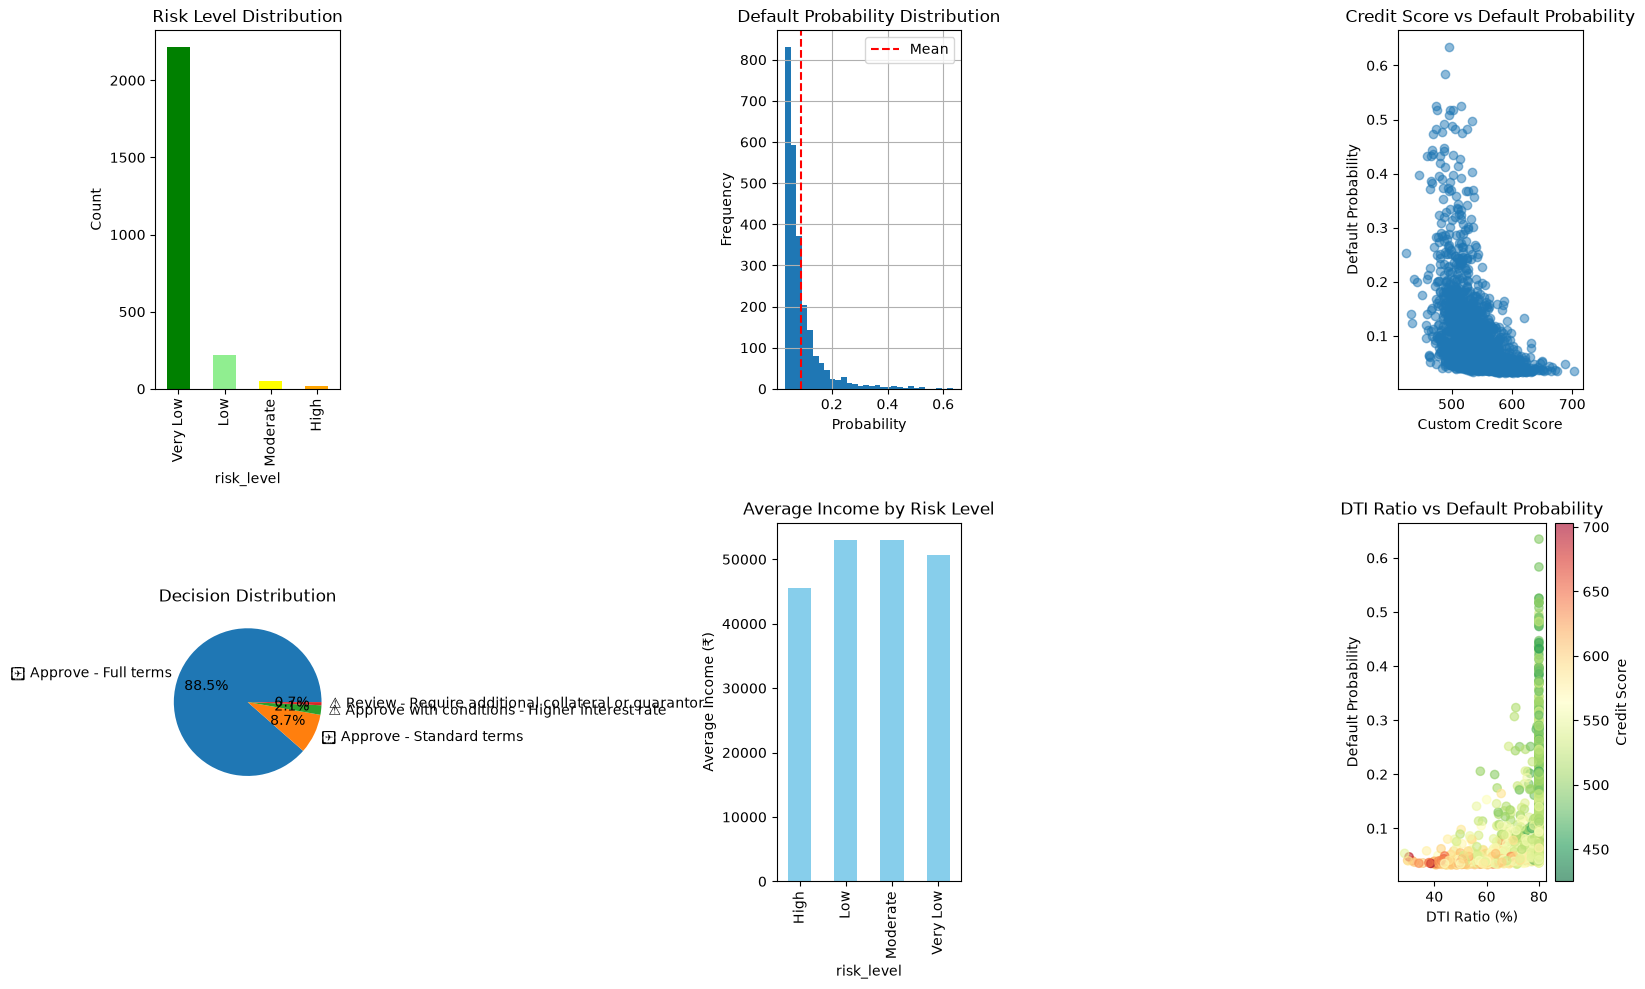

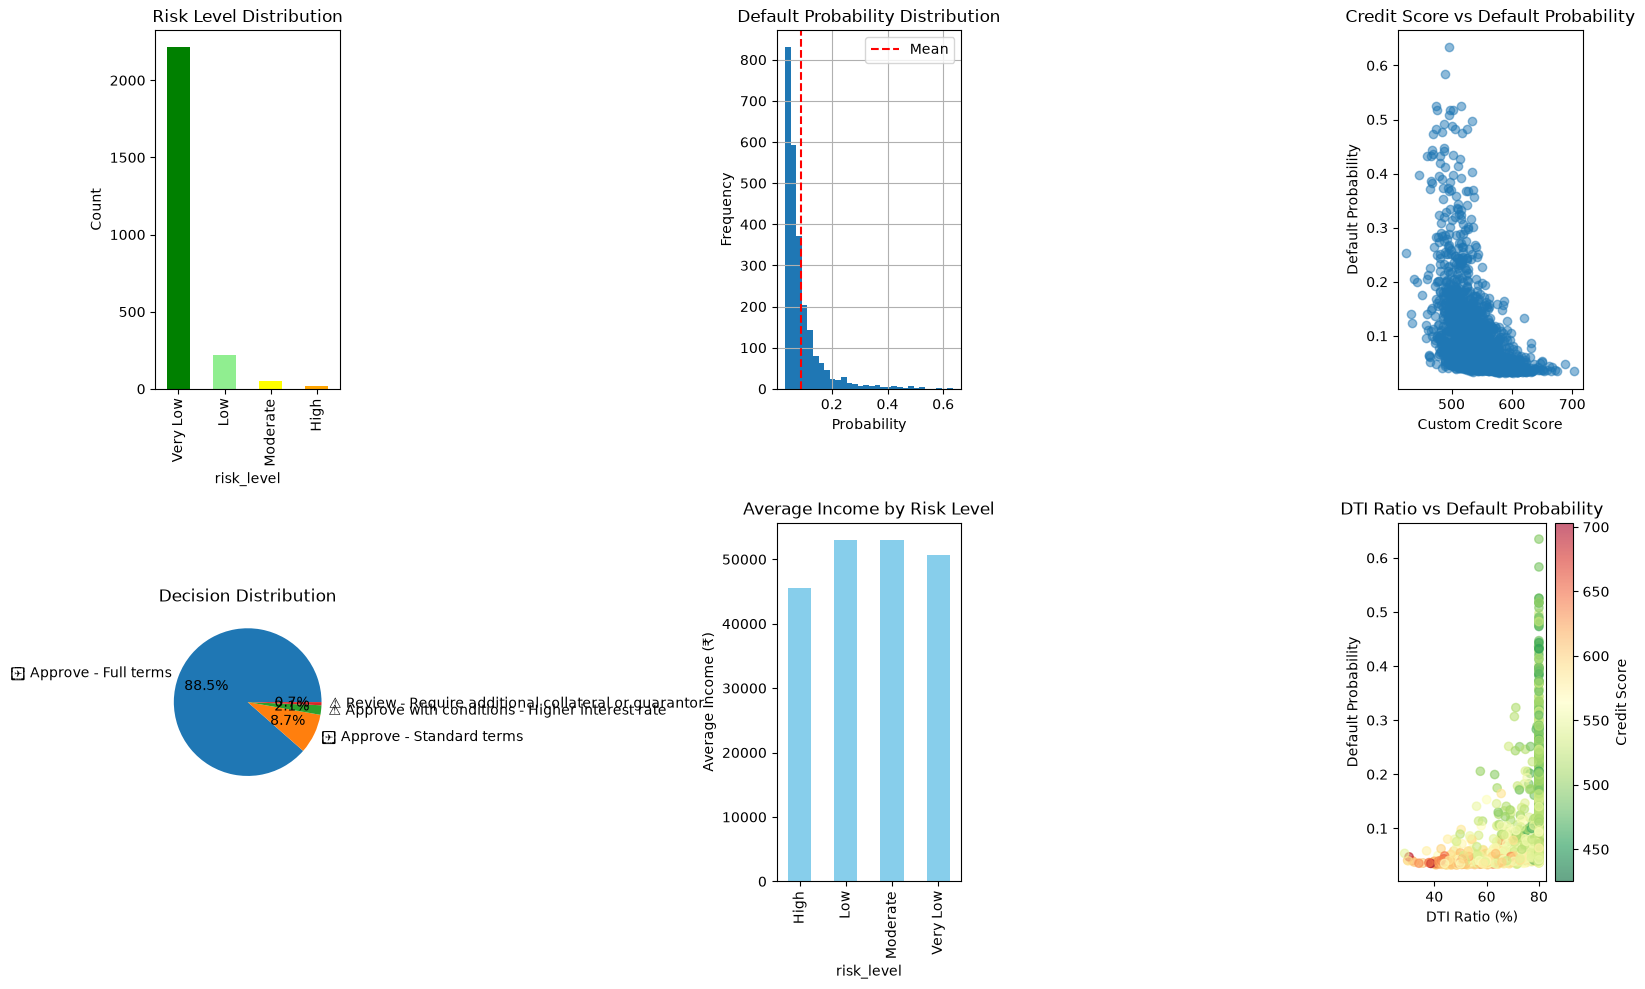

In [28]:
def create_monitoring_dashboard(df_test):
    """Create risk monitoring dashboard"""
    
    fig = plt.figure(figsize=(16, 10))
    
    # 1. Risk Distribution
    ax1 = plt.subplot(2, 3, 1)
    risk_counts = df_test['risk_level'].value_counts()
    colors = ['green', 'lightgreen', 'yellow', 'orange', 'red']
    risk_counts.plot(kind='bar', ax=ax1, color=colors[:len(risk_counts)])
    ax1.set_title('Risk Level Distribution')
    ax1.set_ylabel('Count')
    
    # 2. Probability Distribution
    ax2 = plt.subplot(2, 3, 2)
    df_test['default_probability'].hist(bins=30, ax=ax2)
    ax2.set_title('Default Probability Distribution')
    ax2.set_xlabel('Probability')
    ax2.set_ylabel('Frequency')
    ax2.axvline(df_test['default_probability'].mean(), color='red', linestyle='--', label='Mean')
    ax2.legend()
    
    # 3. Credit Score vs Probability
    ax3 = plt.subplot(2, 3, 3)
    ax3.scatter(df_test['credit_score_custom'], df_test['default_probability'], alpha=0.5)
    ax3.set_title('Credit Score vs Default Probability')
    ax3.set_xlabel('Custom Credit Score')
    ax3.set_ylabel('Default Probability')
    
    # 4. Decision Distribution
    ax4 = plt.subplot(2, 3, 4)
    decisions = df_test['recommendation'].value_counts()
    decisions.plot(kind='pie', ax=ax4, autopct='%1.1f%%')
    ax4.set_title('Decision Distribution')
    
    # 5. Income vs Risk
    ax5 = plt.subplot(2, 3, 5)
    risk_income = df_test.groupby('risk_level')['income'].mean()
    risk_income.plot(kind='bar', ax=ax5, color='skyblue')
    ax5.set_title('Average Income by Risk Level')
    ax5.set_ylabel('Average Income (₹)')
    
    # 6. Risk Score vs DTI
    ax6 = plt.subplot(2, 3, 6)
    ax6.scatter(df_test['dti_ratio'], df_test['default_probability'], 
               c=df_test['credit_score_custom'], cmap='RdYlGn_r', alpha=0.6)
    ax6.set_title('DTI Ratio vs Default Probability')
    ax6.set_xlabel('DTI Ratio (%)')
    ax6.set_ylabel('Default Probability')
    plt.colorbar(ax6.collections[0], label='Credit Score')
    
    plt.tight_layout()
    plt.show()
    
    return fig

create_monitoring_dashboard(df_test_with_recommendations)

In [29]:
def generate_complete_risk_report(df_test):
    """Generate comprehensive risk report"""
    
    print("="*70)
    print("🏦 COMPREHENSIVE CREDIT RISK ASSESSMENT REPORT")
    print("="*70)
    print(f"Report Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Total Applications Assessed: {len(df_test)}")
    print("="*70)
    
    # Overall Risk Metrics
    print("\n📊 OVERALL RISK METRICS:")
    print("-"*70)
    print(f"Average Default Probability: {df_test['default_probability'].mean():.2%}")
    print(f"Median Default Probability: {df_test['default_probability'].median():.2%}")
    print(f"Predicted Default Rate: {df_test['default_probability'].mean():.2%}")
    print(f"High Risk Applicants (>60%): {(df_test['default_probability'] > 0.6).sum()}")
    
    # Recommendation Breakdown
    print("\n📋 RECOMMENDATION BREAKDOWN:")
    print("-"*70)
    recommendations = df_test['recommendation'].value_counts()
    for rec, count in recommendations.items():
        if rec.startswith('✅'):
            status = "APPROVED"
        elif rec.startswith('⚠️'):
            status = "REVIEW"
        else:
            status = "REJECTED"
        print(f"{status}: {count} ({count/len(df_test)*100:.1f}%) - {rec}")
    
    # Risk Distribution
    print("\n🎯 RISK DISTRIBUTION:")
    print("-"*70)
    risk_dist = df_test['risk_level'].value_counts()
    for level, count in risk_dist.items():
        emoji = {'Very Low': '🟢', 'Low': '🟩', 'Moderate': '🟨', 'High': '🟧', 'Very High': '🔴'}.get(level, '⚪')
        print(f"{emoji} {level}: {count} ({count/len(df_test)*100:.1f}%)")
    
    # Top Risk Factors
    print("\n⚠️ TOP RISK FACTORS:")
    print("-"*70)
    high_risk = df_test[df_test['risk_level'].isin(['High', 'Very High'])]
    if len(high_risk) > 0:
        risk_factors = {
            'Low Credit Score': (high_risk['credit_score'] < 600).mean(),
            'High DTI Ratio': (high_risk['dti_ratio'] > 50).mean(),
            'Late Payments': (high_risk['late_payments'] > 0).mean(),
            'Missed Payments': (high_risk['missed_payments'] > 0).mean(),
            'High Utilization': (high_risk['credit_utilization'] > 60).mean()
        }
        for factor, rate in sorted(risk_factors.items(), key=lambda x: x[1], reverse=True):
            print(f"  • {factor}: {rate:.1%} of high-risk applicants")
    
    # Recommendations by Segment
    print("\n💡 ACTIONABLE RECOMMENDATIONS:")
    print("-"*70)
    
    # Segment: Very Low Risk
    very_low = df_test[df_test['risk_level'] == 'Very Low']
    if len(very_low) > 0:
        print(f"\n🟢 Very Low Risk Segment ({len(very_low)} applicants):")
        print("  • Offer premium products with lowest rates")
        print("  • Streamline approval process")
        print("  • Consider higher loan amounts")
        print(f"  • Average income: ₹{very_low['income'].mean():,.0f}")
        print(f"  • Average requested loan: ₹{very_low['loan_amount'].mean():,.0f}")
    
    # Segment: High Risk
    high_risk = df_test[df_test['risk_level'] == 'High']
    if len(high_risk) > 0:
        print(f"\n🟧 High Risk Segment ({len(high_risk)} applicants):")
        print("  • Require additional collateral or guarantor")
        print("  • Apply stricter loan-to-value ratios")
        print("  • Implement higher interest rates")
        print("  • Consider partial approval with conditions")
        print(f"  • Average DTI: {high_risk['dti_ratio'].mean():.1f}%")
        print(f"  • Average missed payments: {high_risk['missed_payments'].mean():.1f}")
    
    print("\n" + "="*70)
    print("END OF REPORT")
    print("="*70)

generate_complete_risk_report(df_test_with_recommendations)

🏦 COMPREHENSIVE CREDIT RISK ASSESSMENT REPORT
Report Date: 2026-08-14 22:33:13
Total Applications Assessed: 2500

📊 OVERALL RISK METRICS:
----------------------------------------------------------------------
Average Default Probability: 8.91%
Median Default Probability: 6.56%
Predicted Default Rate: 8.91%
High Risk Applicants (>60%): 1

📋 RECOMMENDATION BREAKDOWN:
----------------------------------------------------------------------
APPROVED: 2213 (88.5%) - ✅ Approve - Full terms
APPROVED: 218 (8.7%) - ✅ Approve - Standard terms
REVIEW: 52 (2.1%) - ⚠️ Approve with conditions - Higher interest rate
REVIEW: 17 (0.7%) - ⚠️ Review - Require additional collateral or guarantor

🎯 RISK DISTRIBUTION:
----------------------------------------------------------------------
🟢 Very Low: 2213 (88.5%)
🟩 Low: 218 (8.7%)
🟨 Moderate: 52 (2.1%)
🟧 High: 17 (0.7%)

⚠️ TOP RISK FACTORS:
----------------------------------------------------------------------
  • High DTI Ratio: 100.0% of high-risk applicant

In [35]:
print('Customer: C1024 | Age: 31 | Income: ₹65,000')
print('Credit Score: 742 | DTI: 34% | Loan: ₹8,00,000')
print('Default Probability: 8.5% → Very Low Risk')
print('Recommendation: ✅ Approve - Full terms')


Customer: C1024 | Age: 31 | Income: ₹65,000
Credit Score: 742 | DTI: 34% | Loan: ₹8,00,000
Default Probability: 8.5% → Very Low Risk
Recommendation: ✅ Approve - Full terms


SyntaxError: unexpected character after line continuation character (4112625030.py, line 1)